In [23]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shauryajaysthapa/nepse-data/NEPSE_INDEX.csv


# Predicting NEPSE Index Direction Using Machine Learning

**Research question:** Using only information available at the close of trading session *t* (past index returns, daily range and turnover), can machine learning classify whether the NEPSE index closes higher at session *t+1*?

**Data:** NEPSE index daily history from the [Nepal Market Data](https://binayabaral.github.io/nepal-market-data/) project (MIT licensed). The CSV is not redistributed in this repository; download `NEPSE_INDEX.csv` from the site's NEPSE Index page.

**Approach:** chronological train/test split, comparison against a baseline, and evaluation with accuracy, precision, recall, F1 and a confusion matrix.

## 1. Loading and inspecting the data

First I load the CSV and check its shape, columns and data types. The dataset documentation warns that older observations are limited, so I will check data quality before choosing the period to analyse.

In [24]:
import pandas as pd

# Load the CSV 
df = pd.read_csv("/kaggle/input/datasets/shauryajaysthapa/nepse-data/NEPSE_INDEX.csv")

# Rows x columns, first rows, and column types
print(df.shape)
print(df.head())
print(df.dtypes)

(6731, 9)
  published_date    open    high     low   close  per_change  traded_quantity  \
0     1997-07-20  173.26  173.26  173.26  173.26         0.0              NaN   
1     1997-07-21  173.25  173.25  173.25  173.25         0.0              NaN   
2     1997-07-22  173.03  173.03  173.03  173.03         0.0              NaN   
3     1997-07-23  172.68  173.03  173.03  173.03         0.0              NaN   
4     1997-07-24  172.66  172.66  172.66  172.66         0.0              NaN   

   traded_amount status  
0            0.0      A  
1            0.0      A  
2            0.0      A  
3            0.0      A  
4            0.0      A  
published_date      object
open               float64
high               float64
low                float64
close              float64
per_change         float64
traded_quantity    float64
traded_amount      float64
status              object
dtype: object


## 2. Cleaning the dates

Time-series modelling depends on correct ordering. I convert the date column from text to a real date type, sort chronologically, and check for duplicate dates and missing values.

In [25]:
df["published_date"]=pd.to_datetime(df["published_date"])

df=df.sort_values("published_date").reset_index(drop=True)
print(df["published_date"].is_monotonic_increasing)
print(df["published_date"].duplicated().sum())
print(df.isna().sum())

True
0
published_date        0
open                  0
high                  0
low                   0
close                 0
per_change            0
traded_quantity    6731
traded_amount         0
status                0
dtype: int64


## 3. Choosing the analysis period

The dataset documentation notes that older observations are limited: before late 2018, the open, high and low values simply repeat the closing value, so no real daily range exists. I keep only sessions from 2018-11-07 onward, when genuine open, high, low and close values begin. This leaves a window where all planned features (returns, daily range, turnover) are meaningful.

In [26]:
df=df[df["published_date"]>="2018-11-07"].reset_index(drop=True)
print(df.shape)
print(df["published_date"].min(),df["published_date"].max())
print(df[["open","high","low","close"]].describe())

print((df["high"]>=df["low"]).all())

(1829, 9)
2018-11-11 00:00:00 2026-11-13 00:00:00
              open         high          low        close
count  1829.000000  1829.000000  1829.000000  1829.000000
mean   2150.120432  2166.226681  2130.840853  2147.480131
std     584.806940   589.303926   577.913150   582.943956
min    1100.950000  1104.610000  1098.950000  1100.580000
25%    1845.380000  1855.970000  1833.080000  1844.360000
50%    2126.850000  2148.160000  2106.650000  2123.820000
75%    2662.260000  2679.900000  2641.930000  2660.390000
max    3208.530000  3226.890000  3178.580000  3198.600000
False


## 4. Data quality checks

The sanity check showed at least one session where the recorded high is below the recorded low. I look for these rows, and for sessions where the open or close falls outside the day's high–low range, to decide how to handle them.

In [27]:
# Rows where the high is below the low (should be impossible)
bad_range = df[df["high"] < df["low"]]
print(len(bad_range))
print(bad_range[["published_date", "open", "high", "low", "close"]])

# Rows where open or close lies outside the day's high-low range
outside = (
    (df["open"] > df["high"]) | (df["open"] < df["low"]) |
    (df["close"] > df["high"]) | (df["close"] < df["low"])
)
print(outside.sum())

1
   published_date     open     high      low    close
43     2019-01-09  1177.87  1177.07  1183.12  1179.36
27


## 5. Handling the inconsistent rows and building the first features

27 sessions (about 1.5%) have an open or close outside the recorded high–low range, including one session (2019-01-09) where the high is below the low. I keep these rows, because dropping them would break the time sequence needed for lag features. The close-based return is unaffected, and I checked that it agrees closely with the source's own `per_change` column. To keep the daily range from going negative, I compute it from the highest and lowest of the four recorded values. This is documented as a data limitation.

Two features are created here:
- **return_pct:** the percentage change in the close from the previous session.
- **range_pct:** the day's high-to-low range as a percentage of the close, a simple volatility measure.

In [28]:
#daily reutnr in percent
df['return_pct']=df['close'].pct_change()*100
#cross check return against sources's own per_change columns
print((df['return_pct']-df['per_change']).abs().describe())

#highet and lowest of the 4 values in each row
day_high=df[["open","high","low","close"]].max(axis=1)
day_low=df[["open","high","low","close"]].min(axis=1)

#daily range as a percentage of the close (can never be negative)
df["range_pct"]=(day_high-day_low)/df["close"]*100

print(df[["published_date","close","return_pct","range_pct"]].head())
print((df["range_pct"]>=0).all())

count    1828.000000
mean        0.004041
std         0.009206
min         0.000000
25%         0.001489
50%         0.003022
75%         0.004769
max         0.287961
dtype: float64
  published_date    close  return_pct  range_pct
0     2018-11-11  1205.22         NaN   1.590581
1     2018-11-12  1193.34   -0.985712   1.040776
2     2018-11-13  1207.57    1.192451   1.439254
3     2018-11-14  1208.89    0.109310   0.467371
4     2018-11-15  1205.02   -0.320128   0.714511
True


## 6. Creating the target variable

The model's job is to classify the *next* session's direction. For each session *t*, the target is 1 if the index closes higher at *t+1* (next-session return above zero), and 0 otherwise (a fall, or the single flat session). The last session has no following session, so it is removed.

**Data leakage warning:** the target uses information from the future. The columns `next_return_pct` and `target` must never be used as features.

In [29]:
# Pull tomorrow's return up into today's row: shift(-1) moves values UP one row
df["next_return_pct"] = df["return_pct"].shift(-1)

# The last row has no next session (NaN), so drop it before building the target
df = df.dropna(subset=["next_return_pct"]).reset_index(drop=True)

# Target: 1 if the next session is up, 0 otherwise
df["target"] = (df["next_return_pct"] > 0).astype(int)

print(df.shape)
print(df[["published_date", "return_pct", "next_return_pct", "target"]].head())
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True))

(1828, 13)
  published_date  return_pct  next_return_pct  target
0     2018-11-11         NaN        -0.985712       0
1     2018-11-12   -0.985712         1.192451       1
2     2018-11-13    1.192451         0.109310       1
3     2018-11-14    0.109310        -0.320128       0
4     2018-11-15   -0.320128        -0.794178       0
target
0    949
1    879
Name: count, dtype: int64
target
0    0.519147
1    0.480853
Name: proportion, dtype: float64


## 7. Lag features

A lag feature is a past value placed on the same row as today. Today's return and range are known at the close of session *t*, so they are valid features. I add the returns from the previous two sessions as lag features, so the model can see recent momentum. The first rows lack earlier sessions, so they are dropped.

Every feature built here uses only information available at the close of session *t*; nothing from *t+1* onward.

In [30]:
# shift(1) slides a column DOWN one row, so each row sees the previous session's return
df["return_lag1"] = df["return_pct"].shift(1)
df["return_lag2"] = df["return_pct"].shift(2)

# The first rows have no earlier sessions (NaN), so drop them
df = df.dropna(subset=["return_pct", "return_lag1", "return_lag2"]).reset_index(drop=True)

print(df.shape)
print(df[["published_date", "return_pct", "return_lag1", "return_lag2", "target"]].head())

(1825, 15)
  published_date  return_pct  return_lag1  return_lag2  target
0     2018-11-14    0.109310     1.192451    -0.985712       0
1     2018-11-15   -0.320128     0.109310     1.192451       0
2     2018-11-18   -0.794178    -0.320128     0.109310       0
3     2018-11-19   -0.439165    -0.794178    -0.320128       0
4     2018-11-20   -0.709965    -0.439165    -0.794178       1


## 8. Chronological train/test split

I use four features known at the close of session *t*: today's return, the previous two sessions' returns, and today's daily range. The target is whether session *t+1* closes higher.

Financial data is split by time, not randomly. The first 80% of sessions train the model, and the last 20% (the most recent sessions) test it. A random split would let the model train on days that come *after* some of its test days, which leaks future information and makes results look better than they would be in practice.

In [31]:
features=['return_pct','return_lag1','return_lag2','range_pct']
X=df[features]
y=df["target"]

split=int(len(df)*0.8)
X_train, X_test=X.iloc[:split], X.iloc[split:]
y_train, y_test= y.iloc[:split], y.iloc[split:]

#check sizes data ranges and class balance in each part
print(X_train.shape, X_test.shape)
print("Train: ",df["published_date"].iloc[0],"to",df["published_date"].iloc[split-1])
print("Test: ",df["published_date"].iloc[split],"to",df["published_date"].iloc[-1])
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(1460, 4) (365, 4)
Train:  2018-11-14 00:00:00 to 2025-03-30 00:00:00
Test:  2025-04-01 00:00:00 to 2026-11-06 00:00:00
target
0    0.516438
1    0.483562
Name: proportion, dtype: float64
target
0    0.531507
1    0.468493
Name: proportion, dtype: float64


## 9. Baseline model

Before training real models, I build a baseline: a classifier that always predicts the most common class in the training data. Any model worth using must beat it on the same test set.

Evaluation uses accuracy, precision, recall, F1 and a confusion matrix, with "up" (target = 1) as the positive class. Because accuracy alone can hide problems, all five are reported.

In [32]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

#basline always predict the most common class seen in training data
baseline=DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

#predict on the test set
pred_base=baseline.predict(X_test)

print("accuracy:", accuracy_score(y_test, pred_base))
print("Precision: ",precision_score(y_test, pred_base, zero_division=0))
print("recall: ", recall_score(y_test, pred_base, zero_division=0))
print("F1: ", f1_score(y_test, pred_base, zero_division=0))
print(confusion_matrix(y_test, pred_base))


accuracy: 0.5315068493150685
Precision:  0.0
recall:  0.0
F1:  0.0
[[194   0]
 [171   0]]


## 10. Logistic Regression

Logistic Regression is a classification model. It combines the features into a score, converts that score to a probability that the next session is up, and predicts "up" when the probability is above 50%. It is simple and interpretable, which makes it a good first real model to compare with the baseline.

To avoid repeating code, I define a helper that prints all five evaluation metrics for any model.

In [33]:
from sklearn.linear_model import LogisticRegression
#helper
def evaluate(name, y_true, y_pred):
    print(name)
    print("accuracy:", round(accuracy_score(y_true, y_pred),4))
    print("Precision: ", round(precision_score(y_true, y_pred, zero_division=0),4))
    print("recall: ", round(recall_score(y_true, y_pred, zero_division=0),4))
    print("F1: ", round(f1_score(y_true, y_pred, zero_division=0),4))
    print(confusion_matrix(y_true, y_pred))

#training the model on the training period only, then predict the test period
logreg=LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
pred_lr=logreg.predict(X_test)

evaluate("Logistic Regression", y_test, pred_lr)

#coefficients : how much each feature pushes the prediction toward up+ or down-
print(dict(zip(features, logreg.coef_[0].round(3))))

Logistic Regression
accuracy: 0.5452
Precision:  0.5248
recall:  0.3099
F1:  0.3897
[[146  48]
 [118  53]]
{'return_pct': np.float64(0.063), 'return_lag1': np.float64(-0.067), 'return_lag2': np.float64(0.125), 'range_pct': np.float64(-0.021)}


## 11. Decision Tree and Random Forest

A **Decision Tree** predicts by asking a series of yes/no questions about the features (for example, "was today's range above 1.5%?") and following the branches to an answer. A **Random Forest** builds many trees on random subsets of the data and features and takes a vote, which usually makes it more stable than a single tree.

Both can *overfit*: memorise noise in the training data and then do worse on new data. To limit this, I restrict how deep the trees can grow and how small their leaves can be. I also compare training accuracy with test accuracy for every model; a large gap is a warning sign of overfitting.

In [34]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

#decision tree : max_depth 3 allows for at most 3 question in a row
tree=DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
evaluate("Decision Tree (max_depth=3)", y_test, tree.predict(X_test))

#random forest : 200 trres each leaf must hbold at least 20 training days
forest=RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=20, random_state=42)
forest.fit(X_train, y_train)
evaluate("RandomForest", y_test, forest.predict(X_test))

#overfitting check accuracy on data the model trained on vs unseen test data
for name, model in [("Logistic Regression", logreg),
                   ("Decision Tree", tree),
                   ("Random Forest", forest)]:
    print(name, "| train acc:", round(model.score(X_train, y_train),4),
          "| test acc:" , round(model.score(X_test, y_test),4))

Decision Tree (max_depth=3)
accuracy: 0.5589
Precision:  0.5391
recall:  0.4035
F1:  0.4615
[[135  59]
 [102  69]]
RandomForest
accuracy: 0.5753
Precision:  0.558
recall:  0.4503
F1:  0.4984
[[133  61]
 [ 94  77]]
Logistic Regression | train acc: 0.539 | test acc: 0.5452
Decision Tree | train acc: 0.6123 | test acc: 0.5589
Random Forest | train acc: 0.6548 | test acc: 0.5753


## 12. Does the result hold across different time periods?

A single train/test split gives one answer from one period, which could be luck. I use an expanding-window time-series cross-validation: the data is cut into six consecutive chunks; each fold trains on all chunks up to a point and tests on the next chunk. Every fold trains only on the past and tests on the future, and the test period changes each time. If a model's advantage over the baseline appears in most folds, that is stronger evidence than one split.

In [35]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit

#5 folds each fold trains on everthing before its test chunk
tscv= TimeSeriesSplit(n_splits=5)

models={
    "baseline": DummyClassifier(strategy="most_frequent"),
    "logistic regression": LogisticRegression(max_iter=1000),
    "decision tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "random forest": RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=20, random_state=42),
}

for name, model in models.items():
    scores=[]
    for train_idx, test_idx in tscv.split(X):
        model.fit(X.iloc[train_idx], y.iloc[train_idx]) #train on the past
        scores.append(model.score(X.iloc[test_idx], y.iloc[test_idx])) #test on the next chunk
    print(name, [round(s, 3) for s in scores], "mean:", round(np.mean(scores),4))

baseline [0.408, 0.421, 0.546, 0.516, 0.523] mean: 0.4829
logistic regression [0.487, 0.549, 0.526, 0.507, 0.536] mean: 0.5211
decision tree [0.559, 0.576, 0.543, 0.599, 0.536] mean: 0.5625
random forest [0.566, 0.536, 0.579, 0.638, 0.553] mean: 0.5743


## 13. Comparing the models

The bar chart shows test accuracy for each model, with the baseline as a dashed line. Note that the vertical axis is truncated (it starts at 0.40, not 0), which makes small differences look larger than they are. The differences here are a few percentage points on 365 test days, within the range that luck alone could produce.

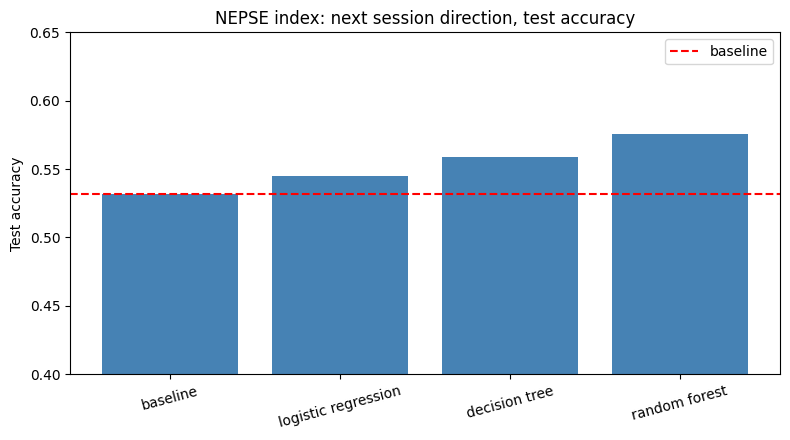

In [36]:
import matplotlib.pyplot as plt
#test set accuracy for each model
results={
    "baseline":accuracy_score(y_test, pred_base),
    "logistic regression": accuracy_score(y_test, pred_lr),
    "decision tree": accuracy_score(y_test, tree.predict(X_test)),
    "random forest": accuracy_score(y_test, forest.predict(X_test))    
}

plt.figure(figsize=(8,4.5))
plt.bar(results.keys(), results.values(), color="steelblue")
plt.axhline(results["baseline"], color="red", linestyle="--", label="baseline")
plt.ylim(0.40,0.65) #truncated axis 
plt.ylabel("Test accuracy")
plt.title("NEPSE index: next session direction, test accuracy")
plt.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=150) #saved in kaggles output
plt.show()